# Formation channels for SMC and LMC metallicity populations

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

COLORS = {0.0001: '#1f4e79',
           0.001: '#2e75b6',
            0.01: '#5ba3d0', 
             0.1: '#f4a261',
             0.2: '#e76f51',
            0.45: '#c0392b', 
             1.0: '#8e1a0e',
             2.0: '#5c0a0a'
             }

LOG_P_MIN = -1.0
LOG_P_MAX = 6.0

In [2]:
def load_metallicity(metallicity, data_folder):
    """Load and process WR phase data for a single metallicity.

    Returns a dict of arrays ready for analysis.
    """
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
    s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

   
    s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                              s1['S1_mass'].values,
                                              s1['S2_mass'].values)
   
    s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                              s2['S2_mass'].values,
                                              s2['S1_mass'].values)
    print(met_str)
    return {
        'time':             np.concatenate([s1['time'].values,               s2['time'].values]),
        'weight':           np.concatenate([s1['weight'].values,             s2['weight'].values]),
        'state':            np.concatenate([s1['state'].values,              s2['state'].values]),
        'key':              np.concatenate([s1.index.get_level_values(0),    s2.index.get_level_values(0)]),
        'star':             np.array(['S1'] * len(s1) + ['S2'] * len(s2)),
        'period':           np.concatenate([s1['orbital_period'].values,     s2['orbital_period'].values]),
        'separation':       np.concatenate([s1_sep,                          s2_sep]),
        'optical_depth':    np.concatenate([s1['optical_depth'].values,      s2['optical_depth'].values]),
        'surface_H':        np.concatenate([s1['S1_surface_h1'].values,      s2['S2_surface_h1'].values]),
        'surface_He':       np.concatenate([s1['S1_surface_he4'].values,     s2['S2_surface_he4'].values]),
        'S1_state':         np.concatenate([s1['S1_state'].values,           s2['S2_state'].values]),
        'model_weight':     np.concatenate([s1['model_weight'].values,       s2['model_weight'].values]),
    }


data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicities = [0.1, 0.2, 0.45]#[0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

1e-01
2e-01
4.5e-01


In [3]:
def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC


def make_binary_mask(d):
    """Return mask for detached/RLO/contact binaries."""
    s = d['state']
    return (s == 'detached') | (s == 'RLO1') | (s == 'contact') | (s == 'RLO2')


# Load observations

In [4]:
LMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/LMC_WRs.csv", sep=",")

# Drop specific BAT99 values
bat99_to_drop = [6, 12, 27, 33, 42, 59, 68, 77, 80, 92, 93, 97, 98, 99, 102, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 116, 117, 118, 119, 126]
LMC_observations = LMC_observations[~LMC_observations['BAT99'].isin(bat99_to_drop)]
obs_single = ~(LMC_observations['Binary?'] != '-')
binary_P_mask = ~obs_single & (LMC_observations['P [d]'] != '-')

print(LMC_observations['P [d]'][binary_P_mask].values)

['17.99' '2.20' '1.90' '2.82' '31.69' '37.59' '5.21' '2.11' '2.75' '2.77']


## LMC

In [5]:
def plot_observations_LMC(ax):
    
    LMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/LMC_WRs.csv", sep=",")

    # Drop specific BAT99 values
    bat99_to_drop = [6, 12, 27, 33, 42, 59, 68, 77, 80, 92, 93, 97, 98, 99, 102, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 116, 117, 118, 119, 126]
    LMC_observations = LMC_observations[~LMC_observations['BAT99'].isin(bat99_to_drop)]
    obs_single = ~(LMC_observations['Binary?'] != '-')
    binary_P_mask = ~obs_single & (LMC_observations['P [d]'] != '-')
    h, edges = np.histogram(np.log10(LMC_observations['P [d]'][binary_P_mask].astype(float)),
                            bins = np.linspace(LOG_P_MIN, LOG_P_MAX, 41),
                            density = True  
                                     )
    ax.fill_between(10**edges[:-1],
                    h*0.1,
                    step='post', 
                    alpha=0.2,
                    zorder=10,
                    label='Observations', color='black', edgecolor='none')
    ax.step(10**edges[:-1], h*0.1, where='post', color='black', linewidth=1,
            zorder=11, alpha=0.6)

## SMC

In [6]:
def plot_observations_SMC(ax):
    
    SMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/SMC_WRs.data", sep=",")

    h, edges = np.histogram(np.log10(SMC_observations['binary_period[days]'][~pd.isna(SMC_observations['binary_period[days]'])].astype(float)),
                            bins = np.linspace(LOG_P_MIN, LOG_P_MAX, 41),
                            density = True  
                                     )
    ax.fill_between(10**edges[:-1],
                    h*0.1,
                    step='post',
                    alpha=0.2,
                    zorder=10,
                    label='Observations', color='black', edgecolor='none')
    ax.step(10**edges[:-1], h*0.1, where='post', color='black', linewidth=1,
            zorder=11, alpha=0.6)

## Plotting

In [7]:
colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[3],
           "Unstable (S2)": colours[2],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }

WNL: 1.0
Stable (S1): 45.428%
Stable (S2): 18.907%
Unstable (S1): 1.675%
Unstable (S2): 4.587%
No MT (S1): 16.458%
No MT (S2): 9.691%
SMC population
WNL: 1.0
Stable (S1): 48.718%
Stable (S2): 18.507%
Unstable (S1): 2.632%
Unstable (S2): 3.756%
No MT (S1): 17.092%
No MT (S2): 6.953%
WNL: 1.0
Stable (S1): 46.643%
Stable (S2): 15.732%
Unstable (S1): 4.690%
Unstable (S2): 4.039%
No MT (S1): 20.745%
No MT (S2): 7.339%


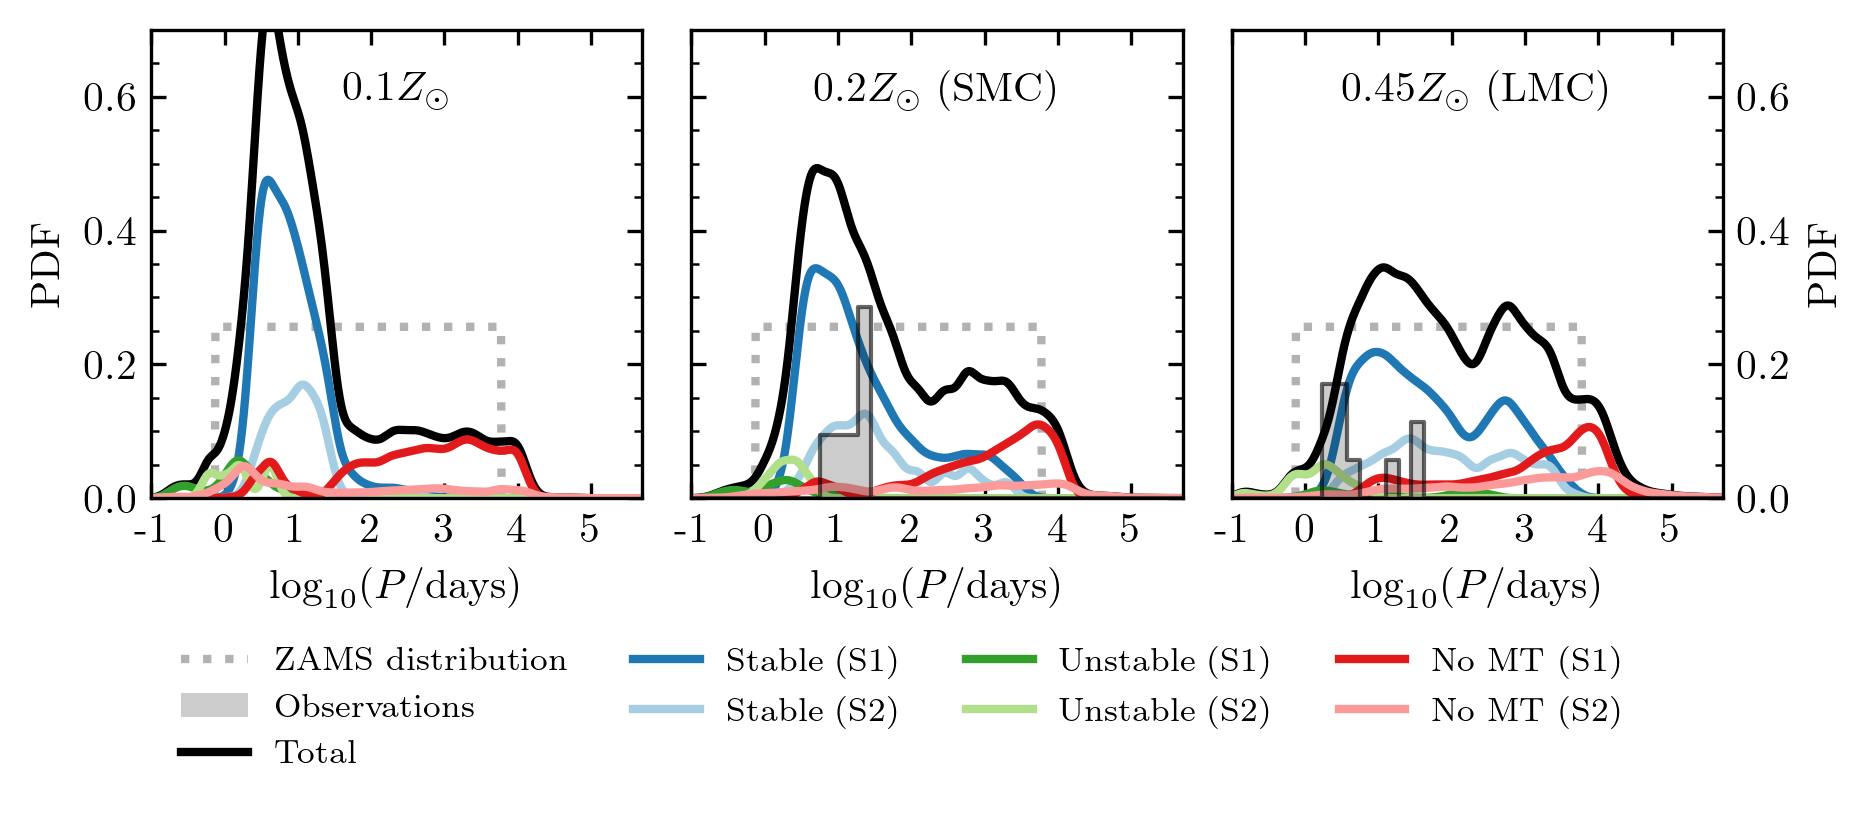

In [8]:
from posydon.popsyn.distributions import Sana12Period, PowerLawPeriod
from posydon.popsyn.synthetic_population import Population
import pandas as pd

metallicity = 0.45
met_str = convert_metallicity_to_string(metallicity)

population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2026_08_14/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (WR_data[metallicity]['star'] == 'S1')
S1_mask_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_stable_indices)))
S1_mask_unstable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_unstable_indices)))
S1_mask_reverse_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_reverse_stable_indices)))
S1_mask_no_MT = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (WR_data[metallicity]['star'] == 'S2')
S2_mask_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_no_MT_indices)))


fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}



flatP = PDF_logP.pdf(10**x_eval)
axes[2].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)


# plot observations
plot_observations_LMC(axes[2])


# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[2].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[2].set_xscale('log')
axes[2].set_xlim(1e-1, 5e5)
axes[2].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[2].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[2].set_ylim(0, 0.7)
axes[2].grid(False)
#axes[2].grid(True, which='major', ls='--', alpha=0.3)
    
axes[2].set_ylabel('PDF')

# move y-axis to the right for the second subplot
axes[2].yaxis.set_label_position("right")
axes[2].yaxis.tick_right()

#axes[2].legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

# SMC population
print("SMC population")

metallicity = 0.2
met_str = convert_metallicity_to_string(metallicity)

population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2026_08_14/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (WR_data[metallicity]['star'] == 'S1')
S1_mask_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_stable_indices)))
S1_mask_unstable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_unstable_indices)))
S1_mask_reverse_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_reverse_stable_indices)))
S1_mask_no_MT = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (WR_data[metallicity]['star'] == 'S2')
S2_mask_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_no_MT_indices)))

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


flatP = PDF_logP.pdf(10**x_eval)
axes[1].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']


# plot observations
plot_observations_SMC(axes[1])


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)



# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[1].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[1].set_xscale('log')
axes[1].set_xlim(1e-1, 5e5)
axes[1].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[1].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[1].set_ylim(0, 0.7)
axes[1].grid(False)
#axes[1].grid(True, which='major', ls='--', alpha=0.3)

# turn of y-axis for the second subplot
axes[1].set_yticklabels([])

axes[1].legend(bbox_to_anchor=(-1.1, -0.25), loc='upper left', ncol=4)


metallicity = 0.1
met_str = convert_metallicity_to_string(metallicity)

population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2026_08_14/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (WR_data[metallicity]['star'] == 'S1')
S1_mask_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_stable_indices)))
S1_mask_unstable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_unstable_indices)))
S1_mask_reverse_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_reverse_stable_indices)))
S1_mask_no_MT = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (WR_data[metallicity]['star'] == 'S2')
S2_mask_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_no_MT_indices)))

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


flatP = PDF_logP.pdf(10**x_eval)
axes[0].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']



# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[0].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[0].set_xscale('log')
axes[0].set_xlim(1e-1, 5e5)
axes[0].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[0].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[0].set_ylim(0, 0.7)
axes[0].grid(False)
#axes[1].grid(True, which='major', ls='--', alpha=0.3)
    
axes[0].set_ylabel('PDF')

#axes[0].legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=4)
plt.subplots_adjust(wspace=0.1,)

axes[0].text(0.5, 0.85, '$0.1Z_\odot$', transform=axes[0].transAxes, ha='center')
axes[1].text(0.5, 0.85, '$0.2Z_\odot$ (SMC)', transform=axes[1].transAxes, ha='center')
axes[2].text(0.5, 0.85, '$0.45Z_\odot$ (LMC)', transform=axes[2].transAxes, ha='center')


figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'
plt.savefig(figure_paths + 'pdf/SMC_LMC_WR_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/SMC_LMC_WR_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

# observations have been rescale with 0.1 factor